In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
from mg_sampling.density.grid import Grid
import MDAnalysis as mda
from MDAnalysis.lib.transformations import rotation_matrix
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm

from mg_sampling import PROJECT_DIR
from mg_sampling.tools import edges_to_range
from mg_sampling.density.utils import indices_to_mask, QuantileTransformation

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Align two maps

In [2]:
old_map = Grid(PROJECT_DIR / 'density/emd_31385.map', file_format='mrc')
new_map = Grid(PROJECT_DIR / 'density/emd_42499.map', file_format='mrc')
new_hmap_1 = Grid(PROJECT_DIR / 'density/emd_42499_half_map_1.map', file_format='mrc')
new_hmap_2 = Grid(PROJECT_DIR / 'density/emd_42499_half_map_2.map', file_format='mrc')
old_u = mda.Universe(PROJECT_DIR / 'density/7ez0.pdb')
new_u = mda.Universe(PROJECT_DIR / 'density/9cbu.pdb')

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [17]:
old_map + new_map

<<class 'mg_sampling.density.grid.Grid'> with (256, 256, 256) bins>

In [27]:
old_map.edges

[array([ -0.32499999,   0.32499999,   0.97499996,   1.62499994,
          2.27499992,   2.92499989,   3.57499987,   4.22499985,
          4.87499982,   5.5249998 ,   6.17499977,   6.82499975,
          7.47499973,   8.1249997 ,   8.77499968,   9.42499965,
         10.07499963,  10.72499961,  11.37499958,  12.02499956,
         12.67499954,  13.32499951,  13.97499949,  14.62499946,
         15.27499944,  15.92499942,  16.57499939,  17.22499937,
         17.87499934,  18.52499932,  19.1749993 ,  19.82499927,
         20.47499925,  21.12499923,  21.7749992 ,  22.42499918,
         23.07499915,  23.72499913,  24.37499911,  25.02499908,
         25.67499906,  26.32499903,  26.97499901,  27.62499899,
         28.27499896,  28.92499894,  29.57499892,  30.22499889,
         30.87499887,  31.52499884,  32.17499882,  32.8249988 ,
         33.47499877,  34.12499875,  34.77499872,  35.4249987 ,
         36.07499868,  36.72499865,  37.37499863,  38.02499861,
         38.67499858,  39.32499856,  39.

In [11]:
# from scipy.spatial.transform import Rotation

# R0 = Rotation.random().as_matrix()

# Test to see if it works with a random initial rotation
# old_map = old_map.rotate(R0, point=old_u.atoms.center_of_mass())
# old_u.atoms.rotate(R0, point=old_u.atoms.center_of_mass())

In [12]:
from mg_sampling.density.align import reorder_residue_atoms
new_u.select_atoms('name O1P').names = 'OP1'
new_u.select_atoms('name O2P').names = 'OP2'
old_ag = reorder_residue_atoms(old_u.select_atoms('nucleic and not type H'))
new_ag = reorder_residue_atoms(new_u.select_atoms('nucleic and not type H and not (resid 22 and name P OP1 OP2)'))
assert np.all(old_ag.names == new_ag.names)

In [13]:
from mg_sampling.density.utils import voxels_around
map_params = {'dx': new_map.delta, 'x0': new_map.origin, 'nbin': new_map.shape}
vox_indices = voxels_around(new_ag, 8, map_params)
new_cc_mask = indices_to_mask(vox_indices, map_params)

map_params = {'dx': old_map.delta, 'x0': old_map.origin, 'nbin': old_map.shape}
vox_indices = voxels_around(old_ag, 8, map_params)
old_cc_mask = indices_to_mask(vox_indices, map_params)

In [14]:
def plot_map_slice(grid: Grid, plane='xy', depth=0.5, depth_mode='fraction', norm=None, cmap='RdBu_r', ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
    
    if norm is None:
        norm = CenteredNorm()

    x_axis, y_axis = ['xyz'.index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, - 1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == 'fraction':
        k = int(depth * len(midpoints))
    elif depth_mode == 'index':
        k = int(depth)
    elif depth_mode == 'coord':
        k = int(np.searchsorted(midpoints, depth, side="left"))
    
    s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))
    im = ax.imshow(grid.grid[s].T, origin='lower', norm=norm, cmap=cmap, extent=extent, **kwargs)

    ax.set_xlabel('xyz'[x_axis])
    ax.set_ylabel('xyz'[y_axis])

    return ax

Text(0.5, 1.0, 'Half map 2')

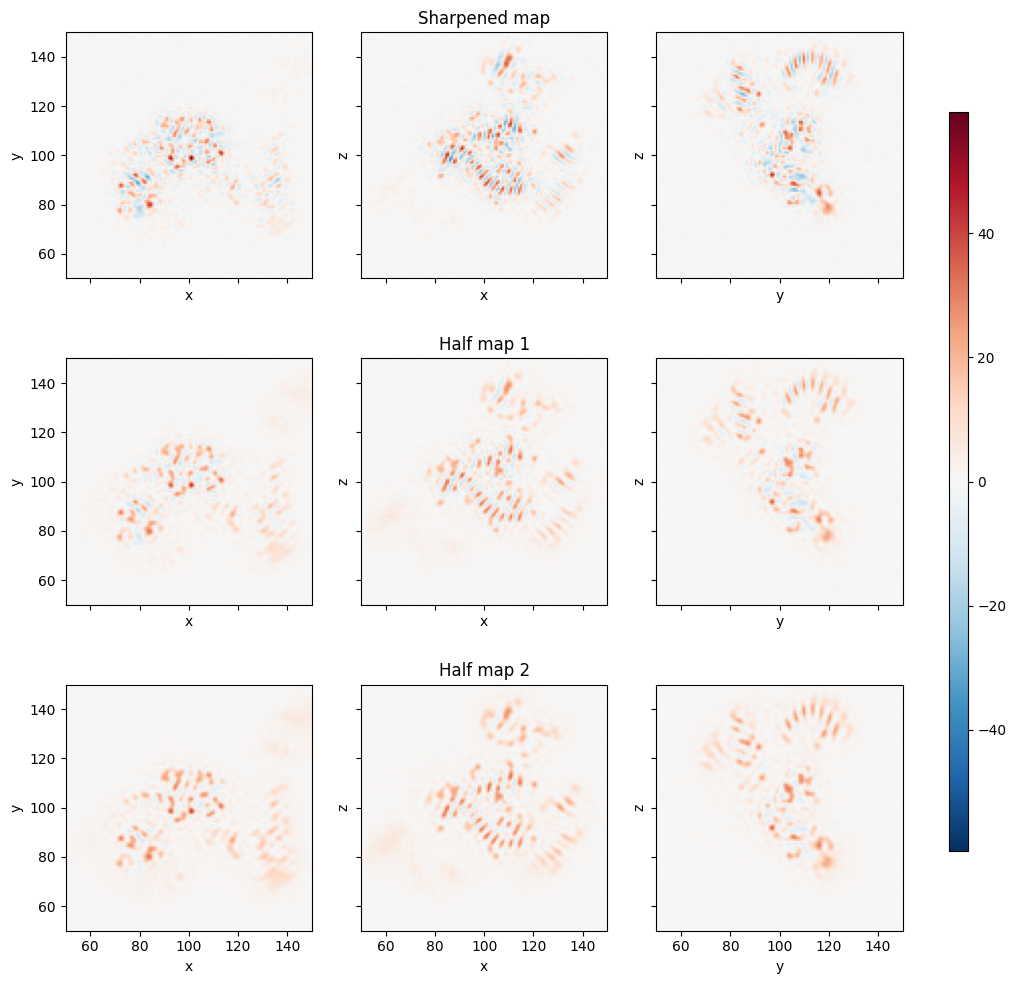

In [16]:
fig, axarr = plt.subplots(ncols=3, nrows=3, sharex=True, sharey=True, figsize=(12, 12))

norm = CenteredNorm()
for i, plane in enumerate(('xy', 'xz', 'yz')):
    ax = plot_map_slice(new_map, ax=axarr[0, i], plane=plane, norm=norm)
    ax = plot_map_slice(new_hmap_1, ax=axarr[1, i], plane=plane, norm=norm)
    ax = plot_map_slice(new_hmap_2, ax=axarr[2, i], plane=plane, norm=norm)

plt.colorbar(axarr[0, 0].images[0], ax=axarr, shrink=0.8, fraction=0.05, aspect=40)
plt.gca().set_xlim(50, 150)
plt.gca().set_ylim(50, 150)
axarr[0, 1].set_title('Sharpened map')
axarr[1, 1].set_title('Half map 1')
axarr[2, 1].set_title('Half map 2')

### Comparison between half-maps

In [27]:
from scipy.stats import linregress

linregress(new_hmap_1.grid[new_cc_mask], new_hmap_2.grid[new_cc_mask])

LinregressResult(slope=np.float64(0.9635024780221809), intercept=np.float64(0.684992925765292), rvalue=np.float64(0.9497572911257236), pvalue=np.float64(0.0), stderr=np.float64(0.0003593709684778043), intercept_stderr=np.float64(0.0013665674778177775))

In [28]:
# We can also do Quantile transformation
def quantilized_cross_correlation(x, y, x_bins=50, y_bins=50):
    p, x_bins = np.histogram(x, bins=x_bins, density=True)
    q, y_bins = np.histogram(y, bins=y_bins, density=True)
    qnorm = QuantileTransformation(p, q, x_range=edges_to_range(x_bins), y_range=edges_to_range(y_bins))
    return linregress(x, qnorm(y)).rvalue

In [29]:
quantilized_cross_correlation(new_hmap_1.grid[new_cc_mask], new_hmap_2.grid[new_cc_mask])

np.float64(0.9545710351536628)

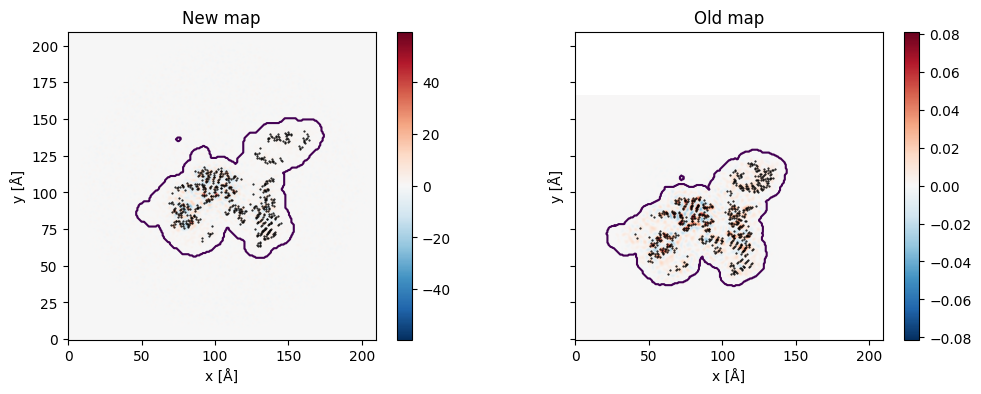

In [ ]:
from matplotlib.colors import CenteredNorm

fig, (ax1, ax2) = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(12, 4))
cmap = 'RdBu_r'

ag = new_ag
m = new_map
cc_mask = new_cc_mask
ax = ax1
norm = CenteredNorm()
midpoints = m.midpoints[0]
L = midpoints[-1] - midpoints[0]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
mask = (ag.positions[:, 2] > L / 2 - 2) & (ag.positions[:, 2] < L / 2 + 2)
im = ax.imshow(m.grid[:, :, len(m.grid)//2].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
plt.colorbar(im, ax=ax)
ax.contour(cc_mask[:, :, len(m.grid)//2].T, origin='lower', extent=extent)
ax.set_title('New map')

ag = old_ag
m = old_map
cc_mask = old_cc_mask
ax = ax2
norm = CenteredNorm()
midpoints = m.midpoints[0]
L = midpoints[-1] - midpoints[0]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
mask = (ag.positions[:, 2] > L / 2 - 2) & (ag.positions[:, 2] < L / 2 + 2)
im = ax.imshow(m.grid[:, :, len(m.grid)//2].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
#ax.scatter(new_ag.positions[mask, 0], new_ag.positions[mask, 1], s=1, color='gray', marker='.')
plt.colorbar(im, ax=ax)
ax.contour(cc_mask[:, :, len(m.grid)//2].T, origin='lower', extent=extent)
ax.set_title('Old map')

for ax in (ax1, ax2):
    ax.set_xlabel('x [Å]')
    ax.set_ylabel('y [Å]')


In [ ]:
# Align old to new with structures
vector = new_ag.center_of_mass() - old_ag.center_of_mass()
R, _ = mda.analysis.align.rotation_matrix(old_ag.positions - old_ag.center_of_mass(), new_ag.positions - new_ag.center_of_mass())
point = new_ag.center_of_mass()

old_ag_aligned = mda.Merge(old_ag).atoms.translate(vector).rotate(R, point=point)

new_ag_aligned = mda.Merge(new_ag).atoms.rotate(R.T, point=point).translate(-vector)

In [ ]:
# Same for map with resample
old_map_aligned = old_map.translate_origin(vector).resample(new_map).rotate(R, point=point)
# Also align new to old
new_map_aligned = new_map.rotate(R.T, point=point).translate_origin(-vector).resample(old_map)

In [ ]:
# Recompute cc_mask for aligned maps
map_params = {'dx': old_map_aligned.delta, 'x0': old_map_aligned.origin, 'nbin': old_map_aligned.shape}
vox_indices = voxels_around(old_ag_aligned, 10, map_params)
old_cc_mask_aligned = indices_to_mask(vox_indices, map_params)

map_params = {'dx': new_map_aligned.delta, 'x0': new_map_aligned.origin, 'nbin': new_map_aligned.shape}
vox_indices = voxels_around(new_ag_aligned, 10, map_params)
new_cc_mask_aligned = indices_to_mask(vox_indices, map_params)

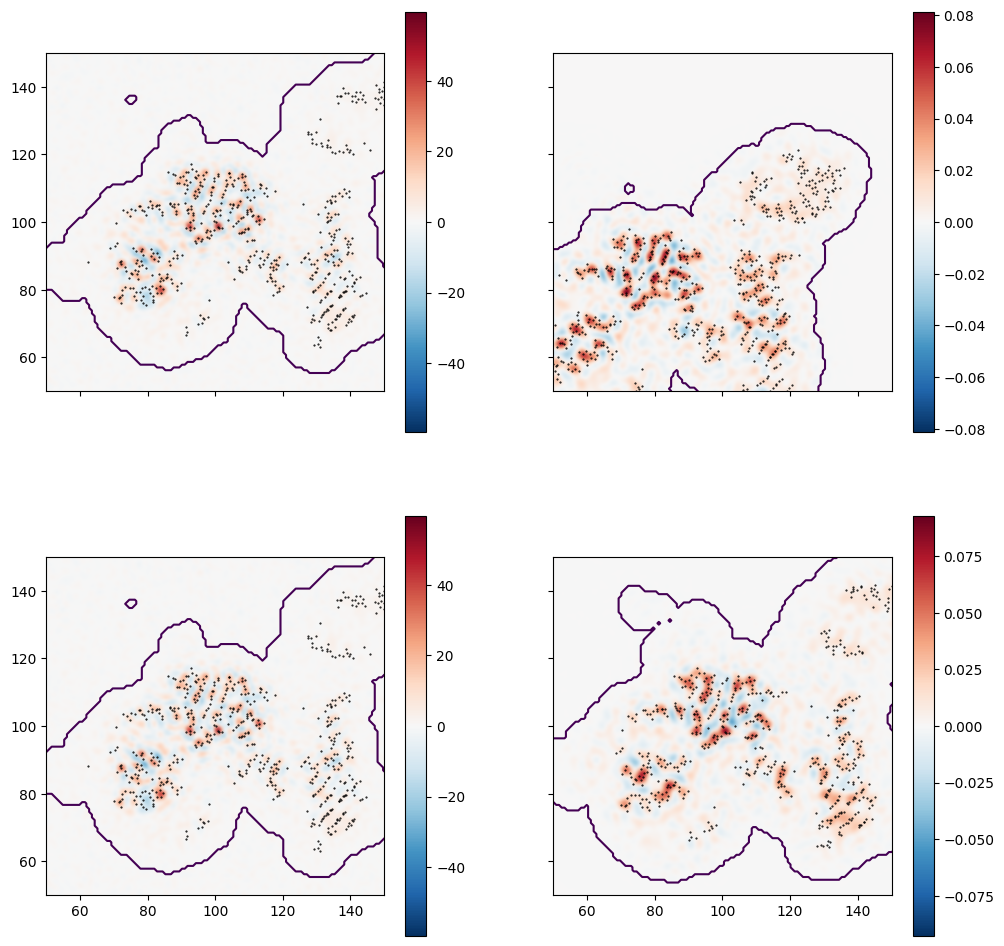

In [ ]:
from matplotlib.colors import CenteredNorm

fig, axarr = plt.subplots(nrows=2, ncols=2, sharex=True, sharey=True, figsize=(12, 12))
cmap = 'RdBu_r'

ag = new_ag
m = new_map
cc_mask = new_cc_mask
ax = axarr[0, 0]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

ag = old_ag
m = old_map
cc_mask = old_cc_mask
ax = axarr[0, 1]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

ag = new_ag
m = new_map
cc_mask = new_cc_mask
ax = axarr[1, 0]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

ag = old_ag_aligned
m = old_map_aligned
cc_mask = old_cc_mask_aligned
ax = axarr[1, 1]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

plt.xlim(50, 150)
plt.ylim(50, 150)
for ax in (ax1, ax2):
    ax.set_xlabel('x [Å]')
    ax.set_ylabel('y [Å]')


In [ ]:
## Unsharpened maps

tempfactors = {
    'old': -14.0,
    'new': -79.23,
}

new_map_unsharp = new_map.apply_tempfactor(-tempfactors['new'])
old_map_unsharp = old_map.apply_tempfactor(-tempfactors['old'])
new_map_aligend_unsharp = new_map_aligned.apply_tempfactor(-tempfactors['new'])
old_map_aligned_unsharp = old_map_aligned.apply_tempfactor(-tempfactors['old'])


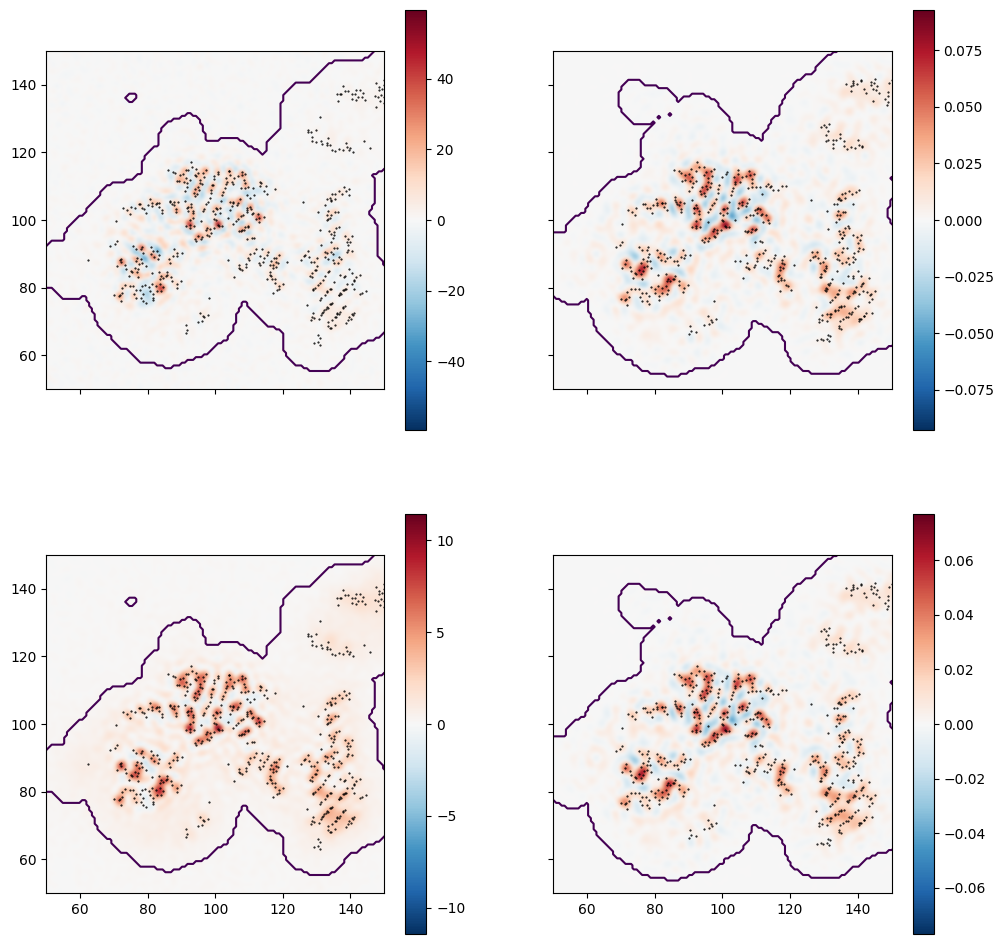

In [ ]:
from matplotlib.colors import CenteredNorm

fig, axarr = plt.subplots(nrows=2, ncols=2, sharex=True, sharey=True, figsize=(12, 12))
cmap = 'RdBu_r'

ag = new_ag
m = new_map
cc_mask = new_cc_mask
ax = axarr[0, 0]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

ag = old_ag
m = old_map_aligned
cc_mask = old_cc_mask_aligned
ax = axarr[0, 1]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

ag = new_ag
m = new_map_unsharp
cc_mask = new_cc_mask
ax = axarr[1, 0]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

ag = old_ag
m = old_map_aligned_unsharp
cc_mask = old_cc_mask_aligned
ax = axarr[1, 1]
k = len(m.midpoints[2])//2
z = m.midpoints[2][k]
x_edges, y_edges, z_edges = m.edges
extent = [x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]]
norm = CenteredNorm()
mask = (ag.positions[:, 2] > z - 2) & (ag.positions[:, 2] < z + 2)
im = ax.imshow(m.grid[:, :, k].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ax.contour(cc_mask[:, :, k].T, origin='lower', extent=extent)
plt.colorbar(im, ax=ax)

plt.xlim(50, 150)
plt.ylim(50, 150)
for ax in (ax1, ax2):
    ax.set_xlabel('x [Å]')
    ax.set_ylabel('y [Å]')


In [ ]:
from mutual_info import compute_mi

In [ ]:
from scipy.stats import linregress

cc_mask = new_cc_mask & old_cc_mask_aligned

res = linregress(old_map_aligned.grid[cc_mask], new_map.grid[cc_mask])
print("Sharpened maps CC:", res)
print("Sharpened maps MI:", compute_mi(old_map_aligned.grid[cc_mask], new_map.grid[cc_mask]))


res = linregress(
    old_map_aligned_unsharp.grid[cc_mask],
    new_map_unsharp.grid[cc_mask],
)
print("Unsharpened maps CC:", res)
print("Unsharpened maps MI:", compute_mi(old_map_aligned_unsharp.grid[cc_mask], new_map_unsharp.grid[cc_mask]))


Sharpened maps CC: LinregressResult(slope=np.float64(207.92794491842102), intercept=np.float64(0.1683414574983475), rvalue=np.float64(0.4268846082778692), pvalue=np.float64(0.0), stderr=np.float64(0.49877414885443166), intercept_stderr=np.float64(0.004545605269813857))


NameError: name 'compute_mi' is not defined

### Fix one map sharpening, vary the other

In [ ]:
from tqdm import tqdm
tempfactors = np.linspace(0, 200, 21)

ccs = []
ccs_unsharp = []
ccs_aligned = []
ccs_aligned_unsharp = []
for B in tqdm(tempfactors):
    _map = new_map.apply_tempfactor(B)
    ccs.append(linregress(_map.grid[new_cc_mask], old_map_aligned.grid[new_cc_mask]).rvalue)
    ccs_unsharp.append(linregress(_map.grid[new_cc_mask], old_map_aligned_unsharp.grid[new_cc_mask]).rvalue)
    _map = new_map_aligned.apply_tempfactor(B)
    ccs_aligned.append(linregress(_map.grid[cc_mask], old_map.grid[cc_mask]).rvalue)
    ccs_aligned_unsharp.append(linregress(_map.grid[cc_mask], old_map_unsharp.grid[cc_mask]).rvalue)

Text(0, 0.5, 'CC')

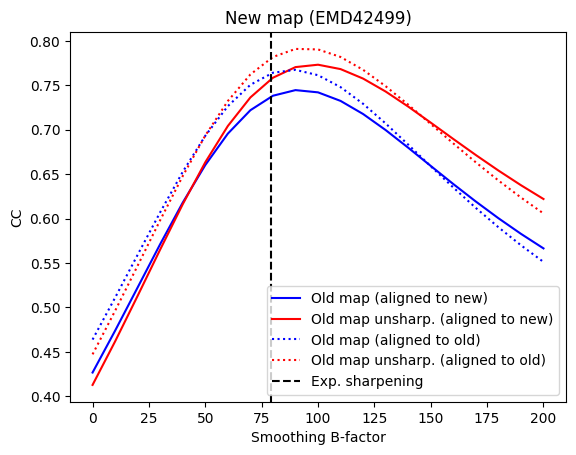

In [ ]:
plt.plot(tempfactors, ccs, label="Old map (aligned to new)", color='blue')
plt.plot(tempfactors, ccs_unsharp, label="Old map unsharp. (aligned to new)", color='red')
plt.plot(tempfactors, ccs_aligned, label="Old map (aligned to old)", color='blue', ls='dotted')
plt.plot(tempfactors, ccs_aligned_unsharp, label="Old map unsharp. (aligned to old)", color='red', ls='dotted')

plt.axvline(79.23, ls='dashed', color='k', label="Exp. sharpening")

plt.legend()
plt.title("New map (EMD42499)")
plt.xlabel("Smoothing B-factor")
plt.ylabel("CC")


In [ ]:
from tqdm import tqdm
tempfactors = np.linspace(0, 200, 21)

ccs = []
ccs_unsharp = []
ccs_aligned = []
ccs_aligned_unsharp = []
for B in tqdm(tempfactors):
    _map = old_map.apply_tempfactor(B)
    ccs.append(linregress(_map.grid[cc_mask], new_map_aligned.grid[cc_mask]).rvalue)
    ccs_unsharp.append(linregress(_map.grid[cc_mask], new_map_aligned_unsharp.grid[cc_mask]).rvalue)
    _map = old_map_aligned.apply_tempfactor(B)
    ccs_aligned.append(linregress(_map.grid[cc_mask], new_map.grid[cc_mask]).rvalue)
    ccs_aligned_unsharp.append(linregress(_map.grid[cc_mask], new_map_unsharp.grid[cc_mask]).rvalue)

  0%|          | 0/21 [00:02<?, ?it/s]


NameError: name 'new_map_aligned_unsharp' is not defined